# 07 · A reference photo for every species in `sweden_species.json`

A visual sanity check, not part of the pipeline: for each of the 61 species
in `data/sweden_species.json`, look up a representative photo on Wikipedia
and show them grouped by `type` (cut flower / foliage / potted), so it is
easy to eyeball whether a `scientific_name` actually looks like what the
`swedish_name` suggests.

**Source and licensing.** Images come from Wikipedia's public REST API
(`/api/rest_v1/page/summary/...`), which almost always serves a Wikimedia
Commons image. These are shown here **for personal reference only** -
Commons images carry their own licence (usually CC BY-SA or public domain,
but not always) and attribution requirements, so do not reuse or publish any
of them without checking that image's own licence page first. Fetched images
are cached under `data/raw/cache/sweden_species_images/` (git-ignored, same
as everything else under `data/raw/`).

**Method.** Try the (cleaned) `scientific_name` first, since it's the least
ambiguous; if that hits a disambiguation page or has no photo, retry with
"(plant)"/"(genus)" appended, then fall back to `english_name`. About a third
of these names are genus-only ("Rosa spp.") or a family ("Orchidaceae"), so
the photo is necessarily a stand-in for the genus/family, not proof of the
exact species - same caveat as everywhere else in this project.

Contents: 1 Load the species list · 2 Look up a photo for each species · 3 Cut
flowers · 4 Foliage · 5 Potted · 6 What's still missing

## 1 · Load the species list

In [1]:
import io
import json
import re
import time

import matplotlib.pyplot as plt
import requests
from PIL import Image

from bouquet_checker.config import DATASET_DIR

%config InlineBackend.figure_format = "jpeg"
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 90}}
plt.rcParams.update({"figure.dpi": 100})

SPECIES_PATH = DATASET_DIR.parent / "sweden_species.json"
species = json.loads(SPECIES_PATH.read_text(encoding="utf-8"))["species"]
by_type = {t: [s for s in species if s["type"] == t] for t in ("cut_flower", "foliage", "potted")}
print(f"{len(species)} species: " + ", ".join(f"{t} {len(v)}" for t, v in by_type.items()))

61 species: cut_flower 33, foliage 15, potted 13


## 2 · Look up a photo for each species

One request per candidate title, politely spaced and retried on a hiccup, cached to disk so
re-running this notebook does not touch the network again. A missing photo
is not unusual - plenty of cultivars and trade names have no Wikipedia page
at all - and is reported in section 6 rather than treated as an error.

In [2]:
IMAGE_CACHE = DATASET_DIR / "cache" / "sweden_species_images"
IMAGE_CACHE.mkdir(parents=True, exist_ok=True)

SESSION = requests.Session()
SESSION.headers.update({
    "User-Agent": "bouquet-toxicity-checker-research/1.0 "
                  "(personal, non-commercial research project)",
})
WIKI_SUMMARY = "https://en.wikipedia.org/api/rest_v1/page/summary/{}"


def slug(text):
    return re.sub(r"[^a-z0-9]+", "-", text.lower()).strip("-")


def clean_scientific_name(name):
    if not name:
        return None
    name = re.sub(r"\s+spp\.?$", "", name)          # "Rosa spp." -> "Rosa"
    name = re.sub(r"\s+cv[.\s].*$", "", name)        # strip a cultivar suffix
    return name.strip() or None


def wiki_summary(title, attempts=3):
    # A single timeout/connection hiccup must not be cached as "no photo
    # exists": retry transient failures before giving up on this title.
    url = WIKI_SUMMARY.format(title.replace(" ", "_"))
    for attempt in range(attempts):
        try:
            response = SESSION.get(url, timeout=20)
        except requests.RequestException:
            time.sleep(1.0 * (attempt + 1))
            continue
        finally:
            time.sleep(0.3)
        if response.status_code == 404:
            return None                        # definitely no such page
        if response.status_code != 200:
            time.sleep(1.0 * (attempt + 1))     # 429 / 5xx: back off and retry
            continue
        try:
            data = response.json()
        except ValueError:
            continue
        thumbnail_url = (data.get("thumbnail") or {}).get("source", "")
        if data.get("type") == "disambiguation" or not thumbnail_url:
            return None                         # a real, definitive answer
        if ".svg" in thumbnail_url.lower():
            return None                         # a diagram/icon, not a photo
        return data
    return None


# Wikipedia's top hit is occasionally not a photo at all (e.g. plain
# "Chrysanthemum" resolves to an article whose lead image is a calligraphy
# diagram of the Chinese characters, not the flower). Rather than guess a
# generic rule, list known exceptions here as they turn up.
TITLE_OVERRIDES = {
    "Krysantemum": "Chrysanthemum morifolium",
}


def candidate_titles(entry):
    override = TITLE_OVERRIDES.get(entry["swedish_name"])
    sci = clean_scientific_name(entry["scientific_name"])
    names = [override] if override else []
    if sci:
        names += [sci, f"{sci} (plant)", f"{sci} (genus)"]
    names += [entry["english_name"], f"{entry['english_name']} (plant)"]
    return names


def fetch_species_image(entry):
    key = slug(entry["swedish_name"])
    meta_path, image_path = IMAGE_CACHE / f"{key}.json", IMAGE_CACHE / f"{key}.jpg"
    if meta_path.exists():
        meta = json.loads(meta_path.read_text(encoding="utf-8"))
        image = Image.open(image_path).convert("RGB") if meta["found"] else None
        return image, meta

    matched_title, data = None, None
    for title in candidate_titles(entry):
        data = wiki_summary(title)
        if data:
            matched_title = title
            break

    if not data:
        meta = {"found": False}
        meta_path.write_text(json.dumps(meta), encoding="utf-8")
        return None, meta

    url = re.sub(r"/\d+px-", "/500px-", data["thumbnail"]["source"])
    image = None
    for attempt in range(3):
        try:
            response = SESSION.get(url, timeout=20)
            response.raise_for_status()
            fetched = Image.open(io.BytesIO(response.content))
            if fetched.mode in ("RGBA", "LA", "PA") or (
                fetched.mode == "P" and "transparency" in fetched.info
            ):
                # composite onto white first: a bare .convert("RGB") turns
                # transparent pixels black instead of leaving them blank
                background = Image.new("RGB", fetched.size, (255, 255, 255))
                background.paste(fetched.convert("RGBA"),
                                 mask=fetched.convert("RGBA").split()[3])
                image = background
            else:
                image = fetched.convert("RGB")
            break
        except Exception:
            time.sleep(1.0 * (attempt + 1))
    if image is None:
        meta = {"found": False}
        meta_path.write_text(json.dumps(meta), encoding="utf-8")
        return None, meta

    image.save(image_path, "JPEG", quality=90)
    meta = {
        "found": True,
        "matched_title": matched_title,
        "page_url": data.get("content_urls", {}).get("desktop", {}).get("page", ""),
    }
    meta_path.write_text(json.dumps(meta), encoding="utf-8")
    return image, meta

In [3]:
results = {}
for n, entry in enumerate(species, 1):
    image, meta = fetch_species_image(entry)
    results[entry["swedish_name"]] = (image, meta)
    if n % 15 == 0 or n == len(species):
        found_so_far = sum(m["found"] for _, m in results.values())
        print(f"  {n}/{len(species)} done ({found_so_far} found so far)", flush=True)

found = sum(meta["found"] for _, meta in results.values())
print(f"{found}/{len(species)} species have a photo")

  15/61 done (15 found so far)


  30/61 done (30 found so far)


  45/61 done (45 found so far)


  60/61 done (60 found so far)


  61/61 done (61 found so far)


61/61 species have a photo


## 3 · Cut flowers

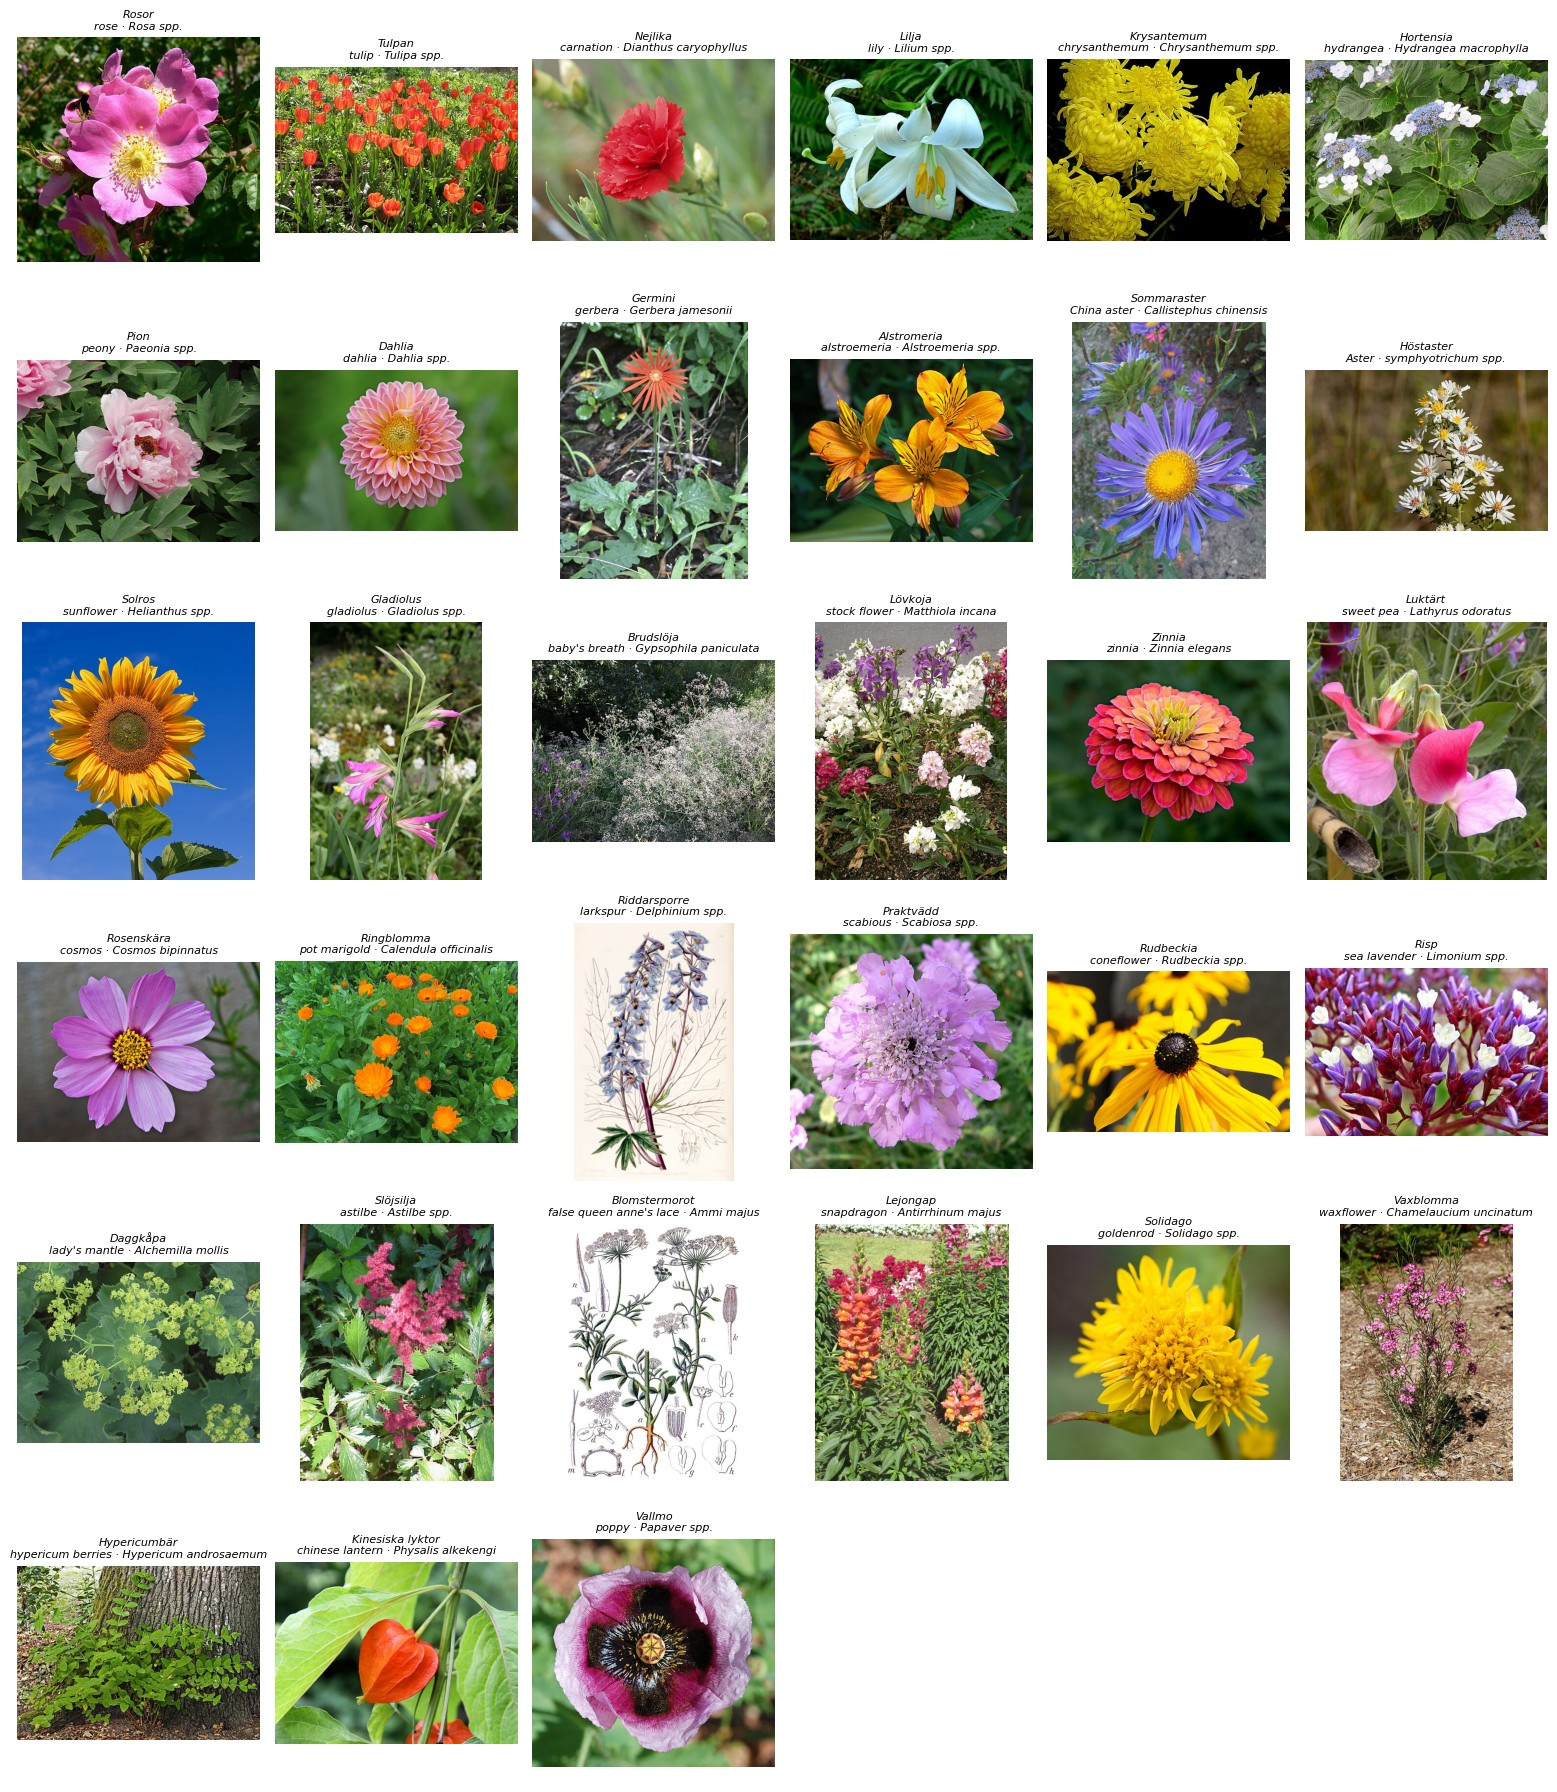

In [4]:
def show_group(entries, cols=6):
    rows = -(-len(entries) // cols)
    fig, axes = plt.subplots(rows, cols, figsize=(2.6 * cols, 3.0 * rows))
    axes = axes.reshape(rows, cols)
    for ax, entry in zip(axes.ravel(), entries):
        image, meta = results[entry["swedish_name"]]
        if image is None:
            ax.imshow([[0.92, 0.92, 0.92]], cmap="gray", vmin=0, vmax=1)
            ax.text(0.5, 0.5, "no photo found", ha="center", va="center",
                    fontsize=9, color="gray", transform=ax.transAxes)
        else:
            ax.imshow(image)
        sci = entry["scientific_name"] or "?"
        ax.set_title(f"{entry['swedish_name']}\n{entry['english_name']} · {sci}",
                     fontsize=8, style="italic" if entry["scientific_name"] else "normal")
    for ax in axes.ravel():
        ax.axis("off")
    plt.tight_layout()
    plt.show()


show_group(by_type["cut_flower"])

## 4 · Foliage

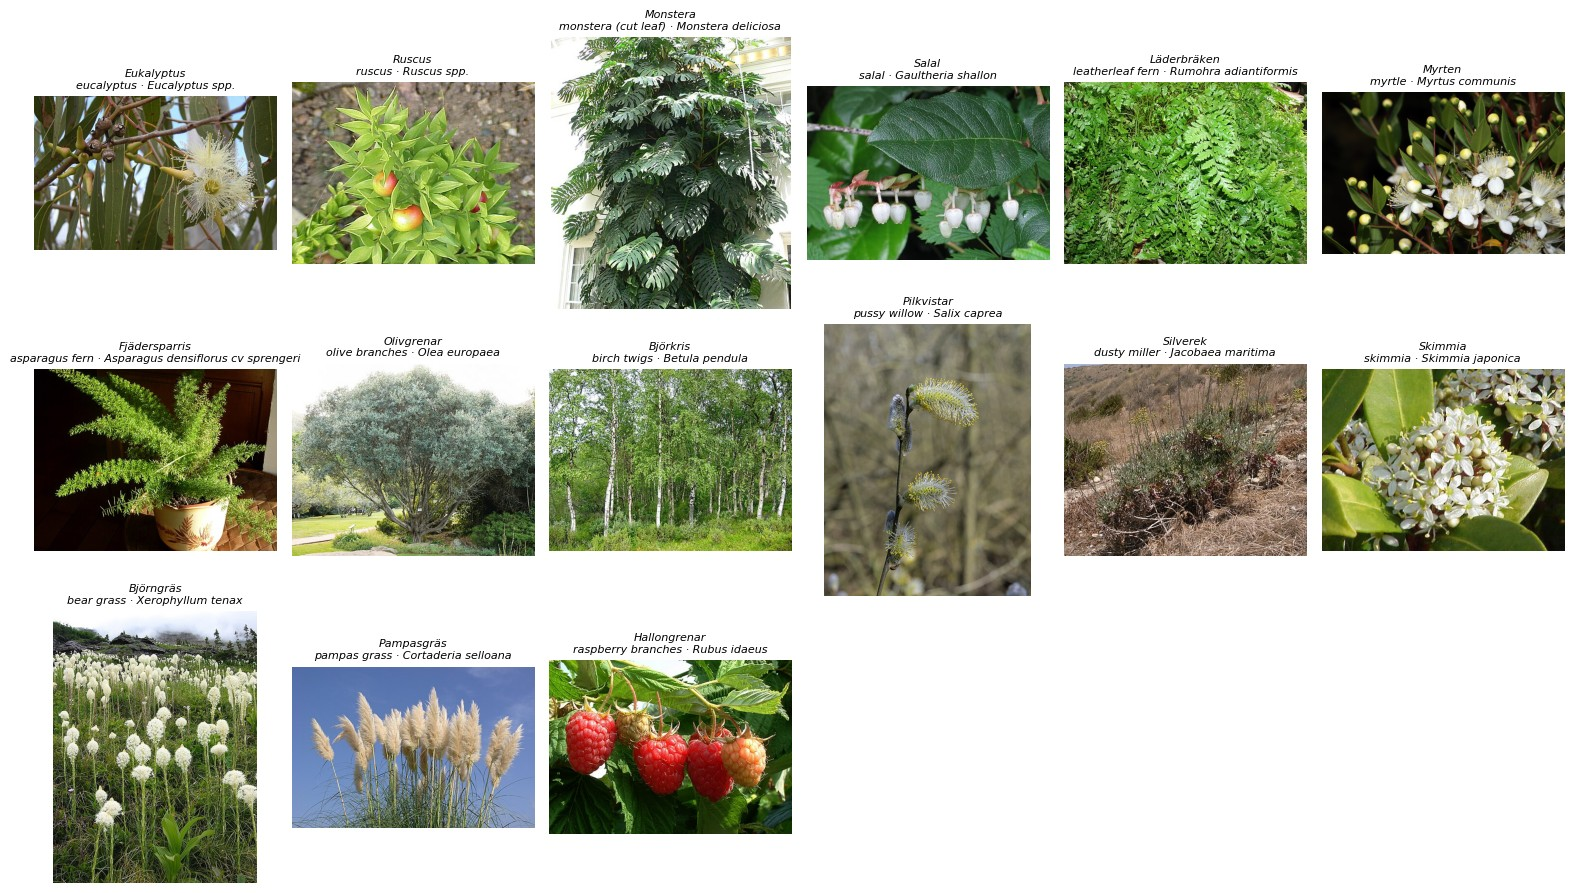

In [5]:
show_group(by_type["foliage"])

## 5 · Potted

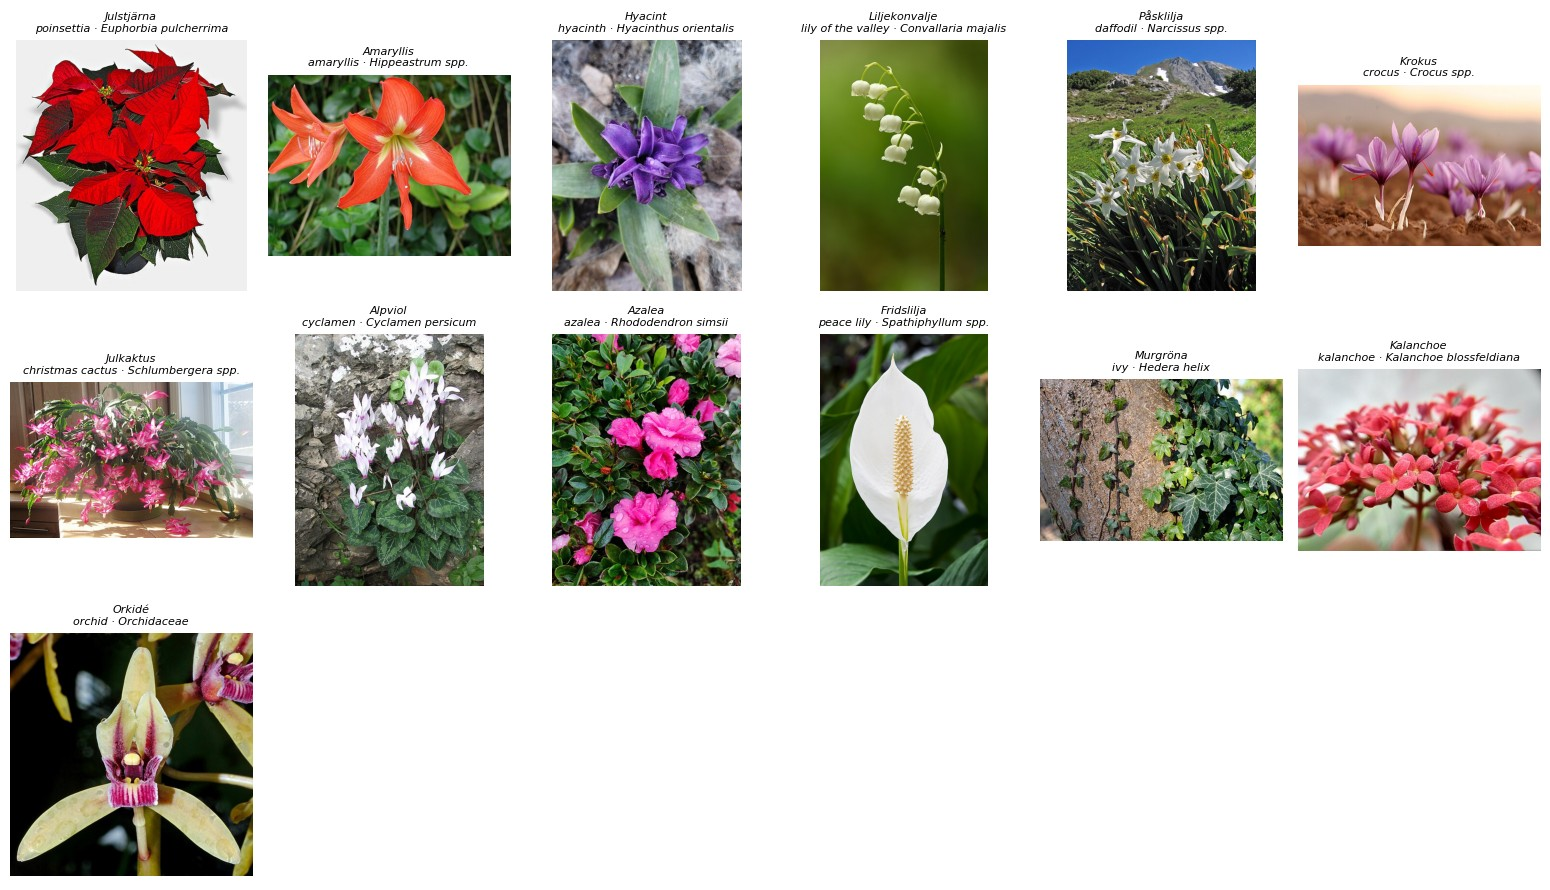

In [6]:
show_group(by_type["potted"])

## 6 · What's still missing

Species with no photo found at all (any of `scientific_name`,
"... (plant)", "... (genus)" or `english_name`), grouped by type. These are
the ones worth sourcing a reference photo for by hand.

In [7]:
missing = [s for s in species if not results[s["swedish_name"]][1]["found"]]
print(f"{len(missing)} of {len(species)} species have no photo")
for t in ("cut_flower", "foliage", "potted"):
    names = [s["swedish_name"] for s in missing if s["type"] == t]
    if names:
        print(f"  {t}: {', '.join(names)}")

0 of 61 species have no photo
